# F7: pCOOP, the orbital basis, and pCOMO's sign (implemented: documentation and warnings)

**Finding** (`notes/theory_audit.md`, F7):
- With `band-projection-params yes no` (projections onto orthonormalized orbitals), the true orbital overlap is
  the identity, so pCOOP between different orbitals is zero. In crawfish's Löwdin basis (`los_orbs=True`) it is
  zero by construction, and with `los_orbs=False` on such data the overlap only reflects band truncation.
- pCOMO has no overlap factor, so its sign depends on how the two orbitals are oriented.

**Fix:** pCOOP warns when it is zero or a truncation artifact, and (new) when the bands don't span the selected
orbitals (`ElecData.orbital_completeness_u`). The README explains how to get meaningful pCOOP:
`band-projection-params no no`, `los_orbs=False`, and enough bands. There is no legacy switch, because no
numbers change.

Data: gas-phase N2 (no-spin, 2×2×2). `N2_nospin` has orthonormalized-orbital projections with 15 bands, and
`N2_nospin_nonortho15/40` have non-orthogonal projections with 15 and 40 bands.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
import warnings
from crawfish.funcs.pcohp import _get_pcohp_tj, _get_pcoop_tj, _get_pcomo_tj

calc_dirs = Path(EXAMPLE_CALC_DIRS_DIR)
datasets = {
    "ortho projections, 15 bands": calc_dirs / "N2_nospin",
    "non-ortho, 15 bands": calc_dirs / "N2_nospin_nonortho15",
    "non-ortho, 40 bands": calc_dirs / "N2_nospin_nonortho40",
}
ORBS = ["s", "py", "pz", "px"]
edatas = {name: load_edata(d, los_orbs=False) for name, d in datasets.items()}

def integrated(ed, func, o=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.sum(ed.occ_tj * func(ed, 0, None, o, 1, None, o, use_cache=False)))

## Orbital completeness and the band-space overlap

`orbital_completeness_u` is how much of each orbital lies in the span of the computed bands. JDFTx normalizes
$\langle\phi|\hat O|\phi\rangle = 1$, so 1 means fully represented. The overlap crawfish can build,
$S = TT^\dagger$, approaches the true $\langle\phi_\mu|\hat O|\phi_\nu\rangle$ only as completeness approaches 1.

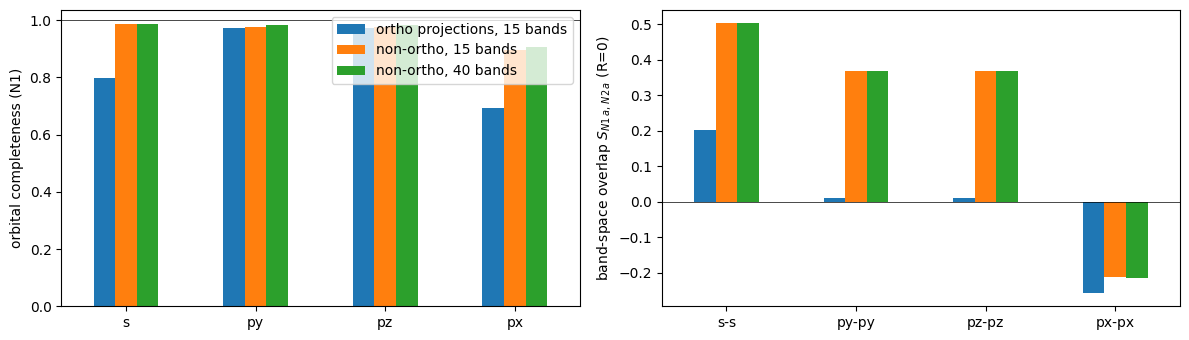

completeness                                          \
   ortho projections, 15 bands non-ortho, 15 bands non-ortho, 40 bands   
s                        0.798               0.986               0.986   
py                       0.974               0.976               0.982   
pz                       0.974               0.976               0.982   
px                       0.691               0.895               0.905   

                 overlap N1-N2                                          
   ortho projections, 15 bands non-ortho, 15 bands non-ortho, 40 bands  
s                        0.201               0.502               0.502  
py                       0.009               0.368               0.369  
pz                       0.009               0.369               0.369  
px                      -0.257              -0.214              -0.215

In [2]:
completeness = pd.DataFrame({name: ed.orbital_completeness_u[:4] for name, ed in edatas.items()}, index=ORBS)
overlap = pd.DataFrame({
    name: {f"{a}-{a}": float(ed.get_mat_r0_suv("s")[0].real[i, 4 + i]) for i, a in enumerate(ORBS)}
    for name, ed in edatas.items()
})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
completeness.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(1, color="k", lw=0.5)
axes[0].set_ylabel("orbital completeness (N1)")
overlap.plot.bar(ax=axes[1], rot=0, legend=False)
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_ylabel(r"band-space overlap $S_{N1\,a,\,N2\,a}$ (R=0)")
fig.tight_layout()
savefig(fig, "F7_completeness_overlap")
plt.show()
pd.concat({"completeness": completeness, "overlap N1-N2": overlap.set_axis(ORBS)}, axis=1).round(3)

With orthonormalized-orbital projections, the "overlap" is just band truncation: py–py is 0.009, against
0.37 with non-orthogonal orbitals. The non-orthogonal overlaps have the textbook signs (σ between parallel px
negative, π positive) and barely change from 15 to 40 bands.

## pCOOP and pCOHP by orbital pair, and the basis dependence

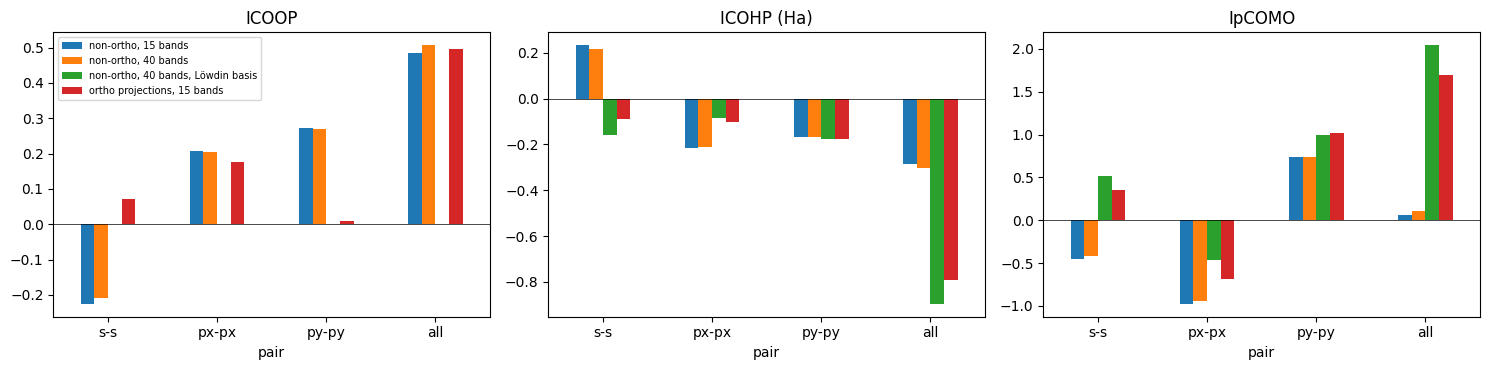

ICOOP  ICOHP (Ha)  IpCOMO
pair  data                                                         
all   non-ortho, 15 bands                0.4839     -0.2843  0.0584
      non-ortho, 40 bands                0.5068     -0.3053  0.1047
      non-ortho, 40 bands, Löwdin basis -0.0000     -0.8958  2.0414
      ortho projections, 15 bands        0.4964     -0.7905  1.6944
px-px non-ortho, 15 bands                0.2083     -0.2167 -0.9753
      non-ortho, 40 bands                0.2032     -0.2102 -0.9469
      non-ortho, 40 bands, Löwdin basis -0.0000     -0.0839 -0.4614
      ortho projections, 15 bands        0.1768     -0.1033 -0.6874
py-py non-ortho, 15 bands                0.2730     -0.1698  0.7410
      non-ortho, 40 bands                0.2706     -0.1679  0.7333
      non-ortho, 40 bands, Löwdin basis -0.0000     -0.1773  0.9910
      ortho projections, 15 bands        0.0089     -0.1786  1.0137
s-s   non-ortho, 15 bands               -0.2252      0.2323 -0.4484
      non-ortho, 40 bands               -0.2084      0.2151 -0.4151
      non-ortho, 40 bands, Löwdin basis -0.0000     -0.1602  0.5208
      ortho projections, 15 bands        0.0713     -0.0884  0.3548

In [3]:
PAIRS = ["s", "px", "py", None]
label = lambda o: "all" if o is None else f"{o}-{o}"
rows = []
for name, ed in edatas.items():
    for o in PAIRS:
        rows.append({"data": name, "pair": label(o), "ICOOP": integrated(ed, _get_pcoop_tj, o),
                     "ICOHP (Ha)": integrated(ed, _get_pcohp_tj, o), "IpCOMO": integrated(ed, _get_pcomo_tj, o)})
lowdin = load_edata(datasets["non-ortho, 40 bands"])  # los_orbs=True: Löwdin basis
for o in PAIRS:
    rows.append({"data": "non-ortho, 40 bands, Löwdin basis", "pair": label(o), "ICOOP": integrated(lowdin, _get_pcoop_tj, o),
                 "ICOHP (Ha)": integrated(lowdin, _get_pcohp_tj, o), "IpCOMO": integrated(lowdin, _get_pcomo_tj, o)})
pair_table = pd.DataFrame(rows).set_index(["pair", "data"]).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["ICOOP", "ICOHP (Ha)", "IpCOMO"]):
    pair_table[col].unstack("data").loc[[label(o) for o in PAIRS]].plot.bar(ax=ax, rot=0, legend=(col == "ICOOP"))
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(col)
axes[0].legend(fontsize=7)
fig.tight_layout()
savefig(fig, "F7_coop_cohp_pairs")
plt.show()
pair_table.round(4)

What this shows:
- **Ortho projections:** pCOOP in the non-orthogonal basis is an artifact (py–py near zero). In the Löwdin
  basis it is zero.
- **Non-orthogonal projections:** pCOOP is chemical and converged with band count. s–s is net antibonding
  (2σg and 2σu* both filled), and pCOHP in the same basis agrees.
- **Basis dependence:** the Löwdin basis gives s–s bonding and a total ICOHP about 3× larger. pCOHP depends on
  the basis (and, in the non-orthogonal basis, on the energy zero: Glassey & Hoffmann 2000). Compare
  calculations in one basis only (open question Q1).
- **pCOMO:** px–px σ is bonding by COOP and COHP, but pCOMO is negative there, because the bonding combination of
  parallel px orbitals has $C^*_\mu C_\nu<0$. pCOMO's sign isn't a bonding indicator.

## Tests

In [4]:
n15, n40, ortho = "non-ortho, 15 bands", "non-ortho, 40 bands", "ortho projections, 15 bands"
assert overlap.loc["py-py", ortho] < 0.02 < 0.3 < overlap.loc["py-py", n40]       # artifact vs. pi overlap
assert overlap.loc["px-px", n40] < -0.1 and overlap.loc["s-s", n40] > 0.3          # textbook signs
for o in PAIRS:
    assert np.isclose(pair_table.loc[(label(o), n15), "ICOOP"], pair_table.loc[(label(o), n40), "ICOOP"], atol=0.03)
assert pair_table.loc[("s-s", n40), "ICOOP"] < 0 < pair_table.loc[("s-s", n40), "ICOHP (Ha)"]
assert np.isclose(pair_table.loc[("all", "non-ortho, 40 bands, Löwdin basis"), "ICOOP"], 0, atol=1e-4)
assert pair_table.loc[("px-px", n40), "ICOOP"] > 0 > pair_table.loc[("px-px", n40), "IpCOMO"]
from crawfish.funcs import get_ipcoop
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    get_ipcoop(edatas[ortho], idcs1=0, idcs2=1, use_cache=False)
    get_ipcoop(lowdin, idcs1=0, idcs2=1, use_cache=False)
messages = " ".join(str(w.message) for w in caught)
assert "orthonormalized orbitals" in messages and "identically zero" in messages
print("All F7 checks passed.")

All F7 checks passed.
